# Bike Sharing Case Study, Part 2: A Testable Hypothesis

**CEO:** *"Riders can't find a bike when they need one, yet bikes sit unused all over the city. Should we just buy more bikes?"*

Part 1 (`note.ipynb`) showed that demand is very uneven across the day. This notebook turns that observation into **one formal, testable hypothesis**, tests it on the data, and then designs the **experiment** that would settle the CEO's question in the field.

## 1. The hypothesis

**Idea:** both complaints can be true at once if demand is concentrated into a few hours. The fleet has to be sized for the busiest hour, so the same bikes sit idle for most of the day. If that's the cause, buying more bikes only helps for a few hours a day; managing the peaks (rebalancing, pricing) is the better lever.

The cleanest version that this dataset can test is about **commuting**, because working days create the sharpest peaks:

> **H₀:** The share of a day's rentals that fall in its 3 busiest hours is the **same** on working days and non-working days.
>
> **H₁:** That share is **higher on working days**. In other words, working-day demand is more concentrated in time, so the bikes needed at peak are high relative to the bikes used across the day.

**Why this metric (top-3-hour share):**
- It measures *concentration*, independent of how busy the day is. A day with 2,000 rentals and a day with 8,000 can be compared directly.
- Three hours roughly matches a commute window (e.g. 07–09 or 17–19).
- It links directly to fleet sizing: bikes needed is driven by the peak, while utilisation is driven by the total.

**Test plan:**
1. **Primary:** one-sided Mann–Whitney U test (no normality assumption) on daily top-3 share, working vs non-working days. Significance level α = 0.05.
2. **Effect size:** difference in medians with a bootstrap 95 % confidence interval, plus the rank-biserial correlation.
3. **Permutation test** as a check that doesn't rely on any distributional assumption.
4. **Controlled check:** regress log(peak hour) on log(daily total) plus day type, weather, season and year. This asks: *for the same daily volume and weather, is the peak higher on working days?*
5. **Robustness:** repeat within each season and year.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.power import TTestIndPower

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["axes.titleweight"] = "bold"
rng = np.random.default_rng(42)

hour = pd.read_csv("hour.csv", parse_dates=["dteday"])
season_map = {1: "Winter", 2: "Spring", 3: "Summer", 4: "Fall"}  # corrected labels (see note.ipynb, 3d)
hour["day_type"] = hour.workingday.map({1: "Working day", 0: "Weekend/holiday"})

## 2. Build the daily concentration metrics

For each day: total rentals, the busiest hour, and the share of rentals in the top 3 hours.

**Assumption:** days with fewer than 20 recorded hours are outages (e.g. Hurricane Sandy), not normal demand, so they are excluded. Missing night hours on other days are zero-rental hours and don't affect the metric.

In [2]:
def top3_share(s):
    return s.nlargest(3).sum() / s.sum()

daily = hour.groupby("dteday").agg(
    total=("cnt", "sum"),
    peak=("cnt", "max"),
    top3=("cnt", top3_share),
    hours=("cnt", "size"),
    workingday=("workingday", "first"),
    weathersit=("weathersit", lambda s: s.mode().iloc[0]),  # most common weather that day
    season=("season", "first"),
    yr=("yr", "first"),
    day_type=("day_type", "first"),
).reset_index()
daily["season_name"] = daily.season.map(season_map)
daily["peak_share"] = daily.peak / daily.total

excluded = daily[daily.hours < 20]
daily = daily[daily.hours >= 20].copy()
print(f"excluded {len(excluded)} outage days:", list(excluded.dteday.dt.strftime("%Y-%m-%d")))
print(f"days analysed: {len(daily)}  (working: {daily.workingday.sum()}, non-working: {(1 - daily.workingday).sum()})")
daily.groupby("day_type")[["total", "peak", "top3"]].median().round(3)

excluded 8 outage days: ['2011-01-18', '2011-01-26', '2011-01-27', '2011-02-22', '2011-08-27', '2011-08-28', '2012-10-29', '2012-10-30']
days analysed: 723  (working: 494, non-working: 229)


,total,peak,top3
day_type,,,
Weekend/holiday,4459.0,410.0,0.274
Working day,4591.0,563.5,0.334


## 3. First look: what does a typical day look like?
Each line shows the average **share of the day's rentals** in each hour, so busy and quiet days count equally.

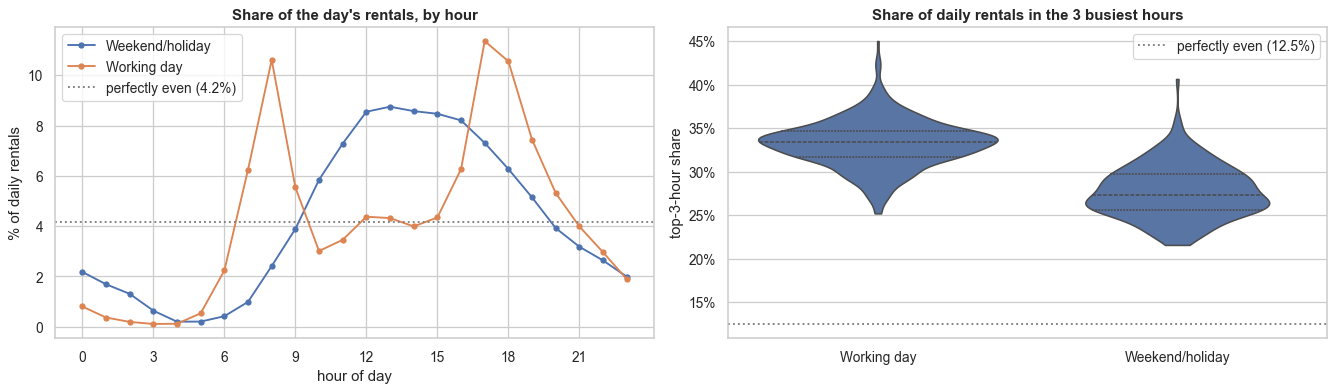

In [3]:
hour["share_of_day"] = hour.cnt / hour.groupby("dteday").cnt.transform("sum")
profile = hour[hour.dteday.isin(daily.dteday)].groupby(["day_type", "hr"]).share_of_day.mean().unstack(0)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
(profile * 100).plot(ax=axes[0], marker="o", ms=4)
axes[0].axhline(100 / 24, color="gray", ls=":", label="perfectly even (4.2%)")
axes[0].set(title="Share of the day's rentals, by hour", xlabel="hour of day", ylabel="% of daily rentals", xticks=range(0, 24, 3))
axes[0].legend(title="")

sns.violinplot(data=daily, x="day_type", y="top3", ax=axes[1], inner="quartile", cut=0,
               order=["Working day", "Weekend/holiday"])
axes[1].axhline(3 / 24, color="gray", ls=":", label="perfectly even (12.5%)")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].set(title="Share of daily rentals in the 3 busiest hours", xlabel="", ylabel="top-3-hour share")
axes[1].legend()
plt.tight_layout(); plt.show()

## 4. Primary test: Mann–Whitney U (one-sided)

In [4]:
work = daily.loc[daily.workingday == 1, "top3"].values
off = daily.loc[daily.workingday == 0, "top3"].values

u, p = stats.mannwhitneyu(work, off, alternative="greater")
rank_biserial = 2 * u / (len(work) * len(off)) - 1

boot = [np.median(rng.choice(work, len(work))) - np.median(rng.choice(off, len(off))) for _ in range(10_000)]
ci = np.percentile(boot, [2.5, 97.5])

print(f"median top-3 share, working days    : {np.median(work):.1%}")
print(f"median top-3 share, weekend/holiday : {np.median(off):.1%}")
print(f"difference in medians               : {np.median(work) - np.median(off):+.1%} points  (95% CI {ci[0]:+.1%} to {ci[1]:+.1%})")
print(f"Mann-Whitney U = {u:,.0f},  one-sided p = {p:.2e}")
print(f"rank-biserial correlation = {rank_biserial:.2f}  (1 = every working day is more concentrated than every non-working day)")

median top-3 share, working days    : 33.4%
median top-3 share, weekend/holiday : 27.4%
difference in medians               : +6.0% points  (95% CI +5.2% to +6.7%)
Mann-Whitney U = 103,484,  one-sided p = 2.01e-72
rank-biserial correlation = 0.83  (1 = every working day is more concentrated than every non-working day)


## 5. Permutation test
If day type didn't matter, shuffling the working/non-working labels shouldn't change the difference. We shuffle 10,000 times and see how often chance alone produces a gap as large as the real one.

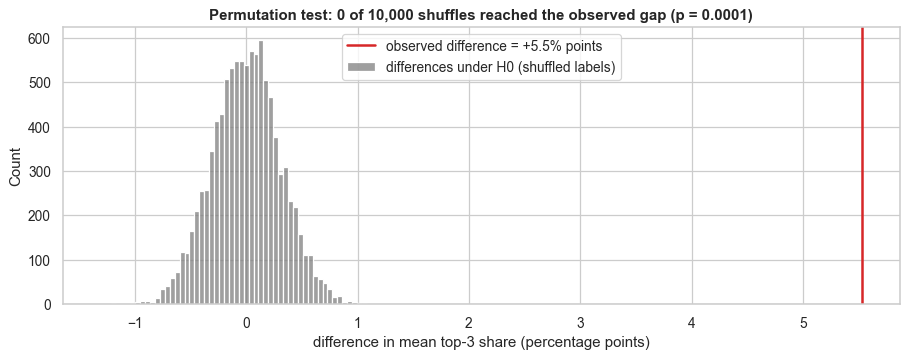

In [5]:
top3 = daily.top3.values
is_work = daily.workingday.values == 1
observed = top3[is_work].mean() - top3[~is_work].mean()
null = np.array([(lambda m: top3[m].mean() - top3[~m].mean())(rng.permutation(is_work)) for _ in range(10_000)])
p_perm = (np.sum(null >= observed) + 1) / (len(null) + 1)

plt.figure(figsize=(12, 4))
sns.histplot(null * 100, bins=60, color="tab:gray", label="differences under H0 (shuffled labels)")
plt.axvline(observed * 100, color="tab:red", lw=2, label=f"observed difference = {observed:+.1%} points")
hits = int(np.sum(null >= observed))
plt.title(f"Permutation test: {hits} of 10,000 shuffles reached the observed gap (p = {p_perm:.4f})")
plt.xlabel("difference in mean top-3 share (percentage points)"); plt.legend()
plt.show()

## 6. Controlled check: same volume, same weather, is the peak still higher?

A skeptic could say working days just have *different* volume or weather. So we model:

$$\log(\text{peak hour}) = \beta_0 + \beta_1 \log(\text{daily total}) + \beta_2\,\text{workingday} + \text{weather} + \text{season} + \text{year}$$

$e^{\beta_2} - 1$ is how much higher the peak hour is on a working day **with the same total rentals and conditions**. Robust (HC3) standard errors guard against unequal variance.

In [6]:
model = smf.ols("np.log(peak) ~ np.log(total) + workingday + C(weathersit) + C(season) + yr", data=daily).fit(cov_type="HC3")
b, (lo, hi) = model.params["workingday"], model.conf_int().loc["workingday"]
print(model.summary().tables[1])
print(f"\nR² = {model.rsquared:.3f}")
print(f"At the same daily volume, the peak hour is {np.exp(b) - 1:+.1%} on working days "
      f"(95% CI {np.exp(lo) - 1:+.1%} to {np.exp(hi) - 1:+.1%}),  p = {model.pvalues['workingday']:.1e}")

                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             -1.5641      0.139    -11.219      0.000      -1.837      -1.291
C(weathersit)[T.2]     0.0305      0.010      3.194      0.001       0.012       0.049
C(weathersit)[T.3]     0.0596      0.040      1.474      0.140      -0.020       0.139
C(season)[T.2]        -0.0078      0.017     -0.450      0.653      -0.042       0.026
C(season)[T.3]        -0.0331      0.019     -1.701      0.089      -0.071       0.005
C(season)[T.4]         0.0072      0.017      0.414      0.679      -0.027       0.041
np.log(total)          0.9040      0.019     48.818      0.000       0.868       0.940
workingday             0.2510      0.008     31.297      0.000       0.235       0.267
yr                     0.0349      0.012      2.863      0.004       0.011       0.059

R² = 0.963
At the same daily volume, the p

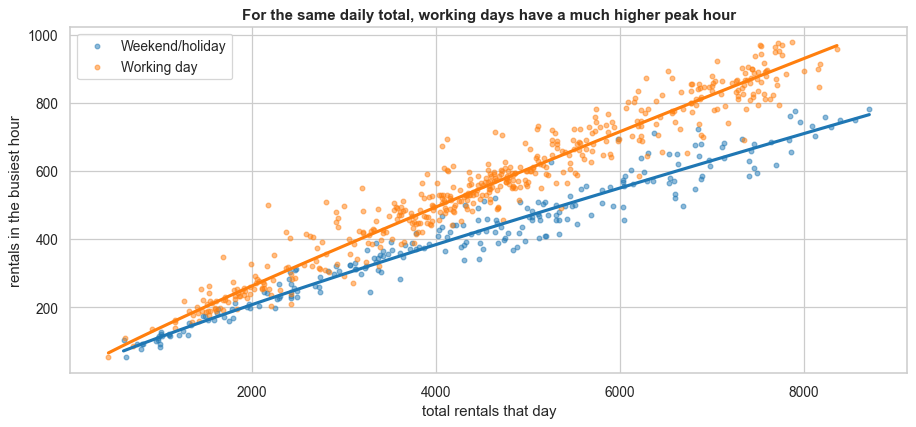

In [7]:
fig, ax = plt.subplots(figsize=(12, 5))
for (label, g), color in zip(daily.groupby("day_type"), ["tab:blue", "tab:orange"]):
    ax.scatter(g.total, g.peak, s=14, alpha=0.5, color=color, label=label)
    fit = np.polyfit(np.log(g.total), np.log(g.peak), 1)
    xs = np.linspace(g.total.min(), g.total.max(), 100)
    ax.plot(xs, np.exp(np.polyval(fit, np.log(xs))), color=color, lw=2.5)
ax.set(title="For the same daily total, working days have a much higher peak hour",
       xlabel="total rentals that day", ylabel="rentals in the busiest hour")
ax.legend(title="")
plt.show()

## 7. Robustness: does it hold in every season and both years?

In [8]:
rows = []
for (yr, season), g in daily.groupby(["yr", "season"]):
    w, o = g.loc[g.workingday == 1, "top3"], g.loc[g.workingday == 0, "top3"]
    rows.append({"year": 2011 + yr, "season": season_map[season],
                 "working median": w.median(), "non-working median": o.median(),
                 "difference": w.median() - o.median(),
                 "p (one-sided)": stats.mannwhitneyu(w, o, alternative="greater").pvalue,
                 "n working": len(w), "n non-working": len(o)})
robust = pd.DataFrame(rows)
robust.style.format({"working median": "{:.1%}", "non-working median": "{:.1%}",
                     "difference": "{:+.1%}", "p (one-sided)": "{:.1e}"})

,year,season,working median,non-working median,difference,p (one-sided),n working,n non-working
0,2011,Winter,34.5%,31.1%,+3.4%,5.2e-06,56,30
1,2011,Spring,33.2%,26.3%,+6.9%,5.3e-13,64,28
2,2011,Summer,32.4%,25.1%,+7.3%,2.3e-12,66,26
3,2011,Fall,33.3%,28.2%,+5.1%,9.2e-12,60,29
4,2012,Winter,34.7%,29.4%,+5.3%,7.7e-11,60,31
5,2012,Spring,33.4%,26.7%,+6.6%,5.9e-13,64,28
6,2012,Summer,32.4%,25.6%,+6.8%,6.7e-13,65,29
7,2012,Fall,33.6%,28.2%,+5.4%,7.1e-12,59,28


## 8. What this means for fleet size

In [9]:
# Fleet needed is set by the busiest hour; utilisation by the average hour.
summary = daily.groupby("day_type").apply(lambda g: pd.Series({
    "median peak hour": g.peak.median(),
    "median average hour": (g.total / 24).median(),
    "peak / average": (g.peak / (g.total / 24)).median(),
    "hours above 50% of peak": (hour[hour.dteday.isin(g.dteday)]
                                 .groupby("dteday").cnt.apply(lambda s: (s > 0.5 * s.max()).sum()).median()),
}), include_groups=False)
summary.round(1)

,median peak hour,median average hour,peak / average,hours above 50% of peak
day_type,,,,
Weekend/holiday,410.0,185.8,2.3,10.0
Working day,563.5,191.3,2.9,6.0


The **average** hour is almost identical on both day types (about 190 rentals). But the working-day **peak** is about 37 % higher (≈ 564 vs 410), and it's concentrated: only about **6 hours** of a working day reach even half the peak, against about 10 on weekends. Fleet requirements follow the peak, while revenue and utilisation follow the average.

## 9. Result

| Test | Result |
|---|---|
| Median top-3-hour share | **33.4 %** on working days vs **27.4 %** on weekends/holidays (an even spread would be 12.5 %) |
| Difference | **+6.0 points**, bootstrap 95 % CI +5.2 to +6.7 |
| Mann–Whitney U (one-sided) | p ≈ 2 × 10⁻⁷², rank-biserial = **0.83** (very large effect) |
| Permutation test | 0 of 10,000 shuffles reached the observed gap |
| Controlled regression | Same daily total, weather, season and year: working-day peak hour is **+28.5 %** (95 % CI +26.5 % to +30.6 %), R² = 0.96 |
| Robustness | Holds in **all 8 season × year groups**, +3.4 to +7.3 points, every p < 10⁻⁵ |

- **We reject H₀.** Working-day demand is much more concentrated in a few hours than non-working-day demand, and the effect is large, not just statistically significant.
- **It isn't explained by volume or weather.** At the same total rentals and conditions, the working-day peak is about 28 % higher.
- **It isn't one period.** It holds in every season of both years. It is smallest in winter 2011, when there was little leisure riding to spread demand out.

**What it means for the CEO's question:** on working days, only a handful of hours carry most of the load. A fleet big enough for 08:00 and 17:00–18:00 is mostly idle the rest of the day. Buying more bikes raises capacity for all 24 hours to fix a problem that exists for about 3–4 of them. That points towards **peak management** (moving bikes to where the commute starts before the peak, incentives to return bikes to empty stations, peak pricing) before buying bikes.

### Caveats (expect to be asked about these)
- **This shows a pattern, not a cause.** It shows *when* demand peaks, not *where* bikes run out. The data is city-wide, with no stations.
- **Demand is censored.** We only see rentals that happened. When the peak runs out of bikes, true peak demand is higher than recorded. That means the real concentration is likely **even stronger** than measured, so the test is conservative.
- **Holidays are grouped with weekends**, as the dataset's `workingday` flag does. There are only about 20 holidays, so this has little effect.
- **Top-3 share is one choice of metric.** The controlled peak regression and the peak/average ratio give the same answer, so the conclusion doesn't hinge on it.

## 10. How to test the CEO's real question in the field: experiment design

The data supports "demand is concentrated in time". The decision the CEO faces is **"buy bikes or manage the peaks?"**, which needs a controlled experiment with station-level data.

**Hypothesis for the field test**
> Targeted rebalancing before the commute peaks reduces *stockouts* at least as much as adding 10 % more bikes, at a lower cost.

**Design: cluster-randomised trial**
| Element | Choice | Why |
|---|---|---|
| Unit | Station **zone** (cluster of nearby stations) | Riders switch between nearby stations, so randomising single stations would leak effects between groups |
| Arms | **A:** control (business as usual) · **B:** pre-peak rebalancing (move bikes to high-demand zones before 07:00 and 16:00) · **C:** +10 % bikes added to the zone | B vs C answers "manage or buy" directly |
| Randomisation | Stratified by zone type (business / residential / leisure) and baseline demand | Keeps arms comparable |
| Primary metric | **Empty-station minutes during peak hours** (07–10, 16–19) per zone-day | Direct, measurable proxy for "can't find a bike" |
| Secondary | Rides per bike per day (utilisation), failed app unlock attempts, cost per avoided stockout | Captures the "bikes sitting unused" side and the economics |
| Guardrails | Full-dock minutes (can't return a bike), complaints, off-peak stockouts | Make sure B doesn't just move the problem |
| Duration | 6 weeks of working days, plus 2 weeks baseline before | Covers weekly cycles; the baseline enables difference-in-differences |
| Analysis | Difference-in-differences with zone fixed effects; standard errors clustered by zone | Removes fixed differences between zones and weather shocks common to all |
| Decision rule | If B cuts stockouts by at least as much as C (non-inferiority) at lower cost, **rebalance instead of buying** | Turns the result into a decision |

**How big does it need to be?** A power calculation for the comparison of two arms, below. The effect size is an **assumption** to agree with operations before launch.

In [10]:
power = TTestIndPower()
rows = []
for d in [0.3, 0.4, 0.5, 0.6]:
    n = power.solve_power(effect_size=d, alpha=0.05, power=0.8, alternative="two-sided")
    rows.append({"effect size (Cohen's d)": d, "zones needed per arm": int(np.ceil(n))})
pd.DataFrame(rows)

,effect size (Cohen's d),zones needed per arm
0,0.3,176
1,0.4,100
2,0.5,64
3,0.6,45


**Reading the power table:** a moderate effect (d ≈ 0.5, e.g. a 20–25 % drop in peak stockout minutes if zones vary by about ±45 %) needs about **64 zones per arm** at 80 % power, if each zone contributes one averaged value. Repeated zone-days over 6 weeks shrink the noise per zone, so fewer zones are likely enough in practice. That depends on how much days vary within a zone, which the 2-week baseline would measure. If the city has too few zones for three arms, a **switchback design** (each zone alternates between treatment and control week by week) is the fallback.

**Next:** Part 3 builds the demand model that turns these peaks into an estimate of **how many bikes are needed**.